# PD model for repeat borrowers: a GRU feature from the raw event history + feature selection + XGBoost

**Task.** Estimate the probability of default for a repeat application at a short-term consumer lender.
Target: **NPL30d90** — 30+ days past due within the first 90 days of the loan. Segments: **L2 / L3 / L4+** — the client's 2nd, 3rd and 4th-or-later loan.

**The solution has three blocks**
1. **A GRU reconstructs a feature from the client's raw event sequence**: issues, payments, prolongations, closures, auto-debits. Feature-factory aggregates lose the order and the micro-dynamics of events. The recurrent network recovers this information as one number, `gru_score` — an out-of-fold logit.
2. **Feature selection** from 300+ candidates: technical filters → leakage → stability (PSI) → IV on valid → boosting importance (gain / SHAP / permutation) against noise "canaries" → MRMR → rank ensemble → correlation → saturation curve.
3. **XGBoost** on the selected features + `gru_score` (stacking). Hyperparameters are tuned by Optuna with a *penalized valid Gini* objective that punishes overfitting. The model is compared with XGBoost without the GRU, with the GRU alone and with a classic WoE scorecard; confidence intervals come from a client-level bootstrap.

**The data are synthetic.** The generator (`src/scoring/synth.py`) simulates the client's hidden risk, its dynamics and the event stream the way a lender's DWH stores it. This makes the project publishable while keeping realistic effects: feature drift, leakage, empty and constant fields, multicollinearity, a rising default rate in the OOT period.

| Section | Contents |
|---|---|
| 1. Data | volumes, default rate, event stream, a client history, feature catalogue |
| 2. Split and PIT | train / valid by client, OOT by time, point-in-time check |
| 3. GRU | tokens, architecture, client-level OOF, quality of `gru_score` |
| 4. Feature selection | funnel 300+ → final set |
| 5. XGBoost | Optuna, final models, WoE scorecard baseline |
| 6. Comparison | Gini, KS, bootstrap ΔGini, segments, ROC |
| 7. Interpretation | SHAP |
| 8. Stability and calibration | monthly Gini, PSI, calibration, risk grades |
| 9. Business impact | strategy curve "approval rate → risk" |
| 10. Deployment | numpy GRU inference, parity with torch, artefacts |
| 11. Conclusions | |

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")   # optuna -> tqdm in a headless kernel

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import xgboost as xgb
from IPython.display import Markdown, display

from scoring import features as fe, gru as G, metrics as mt, modeling as md, plots as pl, selection as sel, sequences as sq, synth
from scoring.config import ARTEFACTS_DIR, AUX_TARGETS, DATA_DIR, FIGURES_DIR, OOT_START, SEED, TARGET

pl.setup_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

FIG = FIGURES_DIR          # every chart is also saved to reports/figures for the README
N_JOBS = 8
N_TRIALS = 40              # Optuna trials per model
GRU_CFG = G.GRUConfig(epochs=10, patience=2, threads=N_JOBS)
T_START = time.time()

## 1. Data

Sources, as in a lender's DWH:
- `applications` — repeat applications with an issued loan and targets (NPL30d90, FPD10/15/30);
- `loans` — contracts: amount, term, issue date, due date;
- `events` — the raw event stream per loan: issue, payment (split into principal, interest and penalty), prolongation, closure, payment reversal, failed auto-debit;
- `external_features` — snapshots at application time: credit bureau, application form, digital footprint.

If the data do not exist yet, the cell below generates them (≈10 seconds). `python scripts/generate_data.py` does the same.

In [2]:
t0 = time.time()
if not (DATA_DIR / "features.parquet").exists():
    _d = synth.generate(synth.SynthConfig())
    synth.save(_d, DATA_DIR)
    fe.build_features(_d.applications, _d.loans, _d.events, _d.external).to_parquet(DATA_DIR / "features.parquet", index=False)
data = synth.load(DATA_DIR)
apps, loans, events = data.applications, data.loans, data.events
feats = pd.read_parquet(DATA_DIR / "features.parquet")
print(f"Applications: {len(apps):,} | clients: {apps.client_id.nunique():,} | loans in history: {len(loans):,} | "
      f"events: {len(events):,} | features: {feats.shape[1] - 1} ({time.time() - t0:.0f} s)")
display(events.head(8))

Applications: 57,657 | clients: 23,389 | loans in history: 119,923 | events: 680,872 | features: 304 (1 s)


,client_id,loan_id,event_time,event,amount,amt_main,amt_percent,amt_penalty,category,plan_end_after
0,1,1,2024-10-11 08:12:00,issue,0.0000,0.0000,0.0000,0.0000,,2024-10-25 12:00:00
1,1,1,2024-10-25 08:19:00,autodebit_fail,0.0000,0.0000,0.0000,0.0000,recurrent,NaT
2,1,1,2024-10-26 08:18:00,autodebit_fail,0.0000,0.0000,0.0000,0.0000,recurrent,NaT
3,1,1,2024-10-27 08:54:00,autodebit_fail,0.0000,0.0000,0.0000,0.0000,recurrent,NaT
4,1,1,2024-11-03 11:26:00,payment,5965.0000,5000.0000,920.0000,45.0000,loan,NaT
5,1,1,2024-11-03 11:26:00,closure,0.0000,0.0000,0.0000,0.0000,,NaT
6,1,45001,2024-11-12 21:25:00,issue,0.0000,0.0000,0.0000,0.0000,,2024-11-19 12:00:00
7,1,45001,2024-11-16 10:57:00,payment,2580.0000,2500.0000,80.0000,0.0000,loan,NaT


applications  clients  npl30d90  fpd30  fpd10
period            segment                                               
OOT: 2026-01…04   L2               5905     5905    0.1865 0.1734 0.3409
                  L3               3819     3819    0.1767 0.1623 0.3168
                  L4+              7059     4173    0.1547 0.1415 0.2690
development: 2025 L2              14878    14878    0.1664 0.1539 0.3058
                  L3               9474     9474    0.1579 0.1460 0.2876
                  L4+             16522     6950    0.1329 0.1204 0.2436

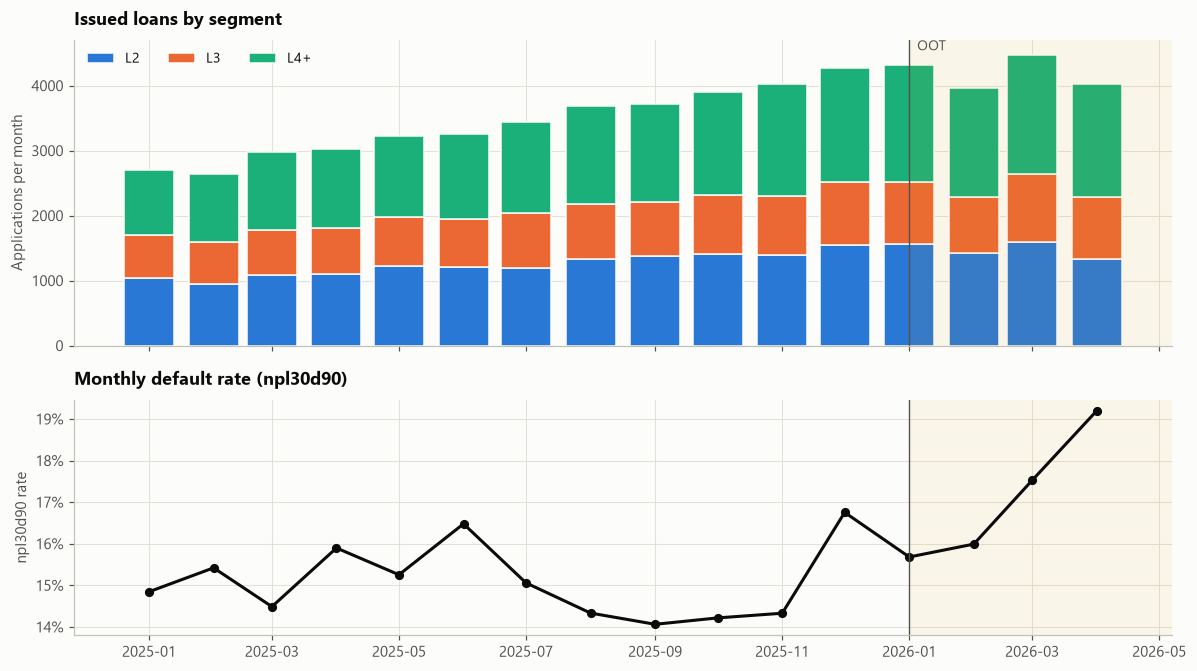

In [3]:
overview = (apps.assign(period=np.where(apps.is_oot.eq(1), "OOT: 2026-01…04", "development: 2025"))
            .groupby(["period", "segment"])
            .agg(applications=("application_id", "size"), clients=("client_id", "nunique"),
                 npl30d90=(TARGET, "mean"), fpd30=("fpd30", "mean"), fpd10=("fpd10", "mean")))
display(overview)
pl.monthly_overview(apps, TARGET, OOT_START, FIG)
plt.show()

The default rate in the OOT period is higher than in 2025: the generator includes a macro shift starting in autumn 2025. This happens on real data too, and it shows up later in calibration (section 8): the ranking holds, but the PD level has to be recalibrated.

**What the raw history looks like.** Below are one client's loans and events up to the moment the application is scored. Bars are loans, the vertical tick is the due date. This is exactly the sequence the GRU receives.

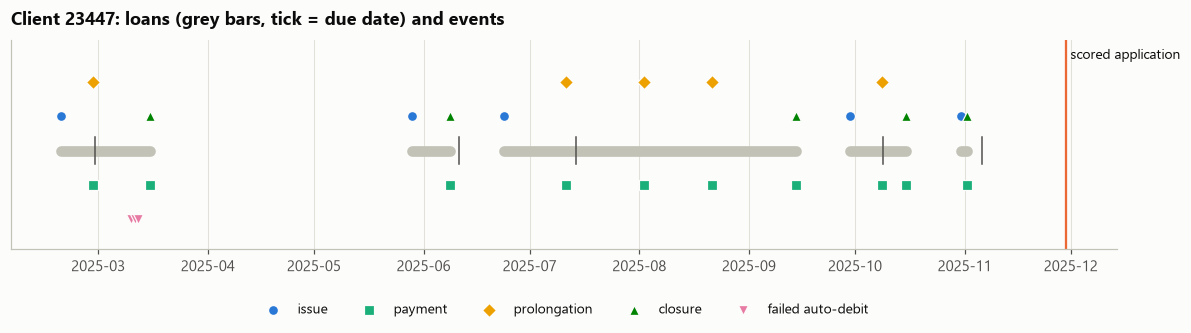

In [4]:
adf = set(events.loc[events.event.eq("autodebit_fail"), "client_id"])
prl = set(events.loc[events.event.eq("prolongation"), "client_id"])
cand = apps[apps.loan_no.between(5, 6) & apps.client_id.isin(adf & prl)]
ex = cand.sample(1, random_state=7).iloc[0]
hist_ev = events[(events.client_id == ex.client_id) & (events.event_time < ex.application_date)]
pl.client_timeline(hist_ev, loans[loans.loan_id.isin(hist_ev.loan_id)], ex.client_id, ex.application_date, FIG)
plt.show()

**Feature catalogue.** The factory computes aggregates over the client's previous loans and payments in 30 / 60 / 90 / 180 / 365-day windows and over the whole history: delinquency, prolongations, early repayment, partial payments, penalties, trends, recency-weighted means, gaps between loans. Bureau, application form and digital footprint are added on top. Everything is computed strictly as of the application time.

In [5]:
FEATURES = [c for c in feats.columns if c != "application_id"]
catalog = fe.feature_catalog(FEATURES)
display(catalog.groupby(["group", "group_name"]).size().rename("features").reset_index())
display(catalog.groupby("group").head(3)[["group", "feature"]].reset_index(drop=True))

,group,group_name,features
0,app,Application form and loan request,31
1,bki,Credit bureau,44
2,coll,Collections,1
3,dig,Digital footprint,35
4,hist,Internal credit history,193


,group,feature
0,hist,hist_loans_cnt_30d
1,hist,hist_amount_sum_30d
2,hist,hist_amount_mean_30d
3,app,app_loan_number
4,app,app_requested_amount
5,app,app_requested_term
6,bki,bki_inq_7d
7,bki,bki_inq_30d
8,bki,bki_inq_90d
9,dig,dig_form_fill_time_sec


## 2. Sample split and point-in-time

- **OOT** — applications from 2026-01…04. This is an honest holdout: it takes no part in feature selection or hyperparameter tuning.
- **train / valid** — 2025 applications split **by client**: 20% of clients go to valid entirely. With a random split by application, the same clients land in both parts, and valid starts rewarding models that memorise people. Neural networks are especially prone to this.
- The GRU OOF folds are built by client as well.

In [6]:
df = apps.merge(feats, on="application_id", validate="one_to_one")
is_oot = df.is_oot.eq(1).to_numpy()
fold = np.full(len(df), -1)
fold[~is_oot] = G.client_folds(df.client_id.to_numpy()[~is_oot], 5, SEED)
df["split"] = np.where(is_oot, "oot", np.where(fold == 0, "valid", "train"))
assert not set(df.loc[df.split.eq("train"), "client_id"]) & set(df.loc[df.split.eq("valid"), "client_id"])
display(df.groupby("split").agg(applications=("application_id", "size"), clients=("client_id", "nunique"),
                                date_from=("application_date", "min"), date_to=("application_date", "max"),
                                npl30d90=(TARGET, "mean"))
          .loc[["train", "valid", "oot"]])

,applications,clients,date_from,date_to,npl30d90
split,,,,,
train,32518,13984,2025-01-01 00:45:00,2025-12-31 21:36:00,0.1518
valid,8356,3496,2025-01-01 04:59:00,2025-12-31 23:35:00,0.1473
oot,16783,10110,2026-01-01 00:36:00,2026-04-29 23:39:00,0.1709


**Point-in-time check.** For 300 random applications the history features are recomputed from scratch on events truncated at the application time and compared with the batch calculation. If the batch calculation used anything from the future or mixed up rows between applications, the values would differ.

> During development this check caught a real bug: recency features were assigned as a raw array without index alignment and "slid" between applications. After the fix there are no mismatches.

In [7]:
ids = df.sample(300, random_state=SEED).application_id.tolist()
recomputed = fe.pit_recompute(ids, apps, loans, events).set_index("application_id")
batch = feats.set_index("application_id").loc[ids, recomputed.columns]
mismatch = ((recomputed - batch).abs() > 1e-9) & ~(recomputed.isna() & batch.isna())
print(f"Recomputed: {len(ids)} applications × {recomputed.shape[1]} history features. Mismatches: {int(mismatch.values.sum())}")
assert mismatch.values.sum() == 0

Recomputed: 300 applications × 199 history features. Mismatches: 0


## 3. GRU: reconstructing a feature from the event sequence

**A token** is everything that happened to one loan within one minute (for example, a payment and a closure). Token fields use only information known at the token time (29 fields):

| Group | Fields |
|---|---|
| contract | `log_loan_sum`, `log_loan_term`, `loan_no` |
| loan state | `loan_age`, `dpd_at_token`, `days_to_due_after`, `ext_days`, `late_vs_first_plan`, `principal_left_ratio`, `paid_ratio`, `n_prol` |
| client portfolio | `open_loans`, `dt_prev` |
| calendar | `dow_sin/cos`, `hour_sin/cos` |
| payment amounts | `amt_main`, `amt_percent`, `amt_penalty` (% of the loan amount, signed log) |
| event type | `ev_issue`, `ev_payment`, `ev_prolongation`, `ev_closure`, `ev_cancel`, `ev_autodebit_fail`, `cat_loan`, `cat_prolongation`, `cat_recurrent` |

The token's age relative to the application is added on the fly when a batch is built. The last 128 tokens strictly before the application are used.

**Model:**
```
token → Linear(29+1 → 64) + GELU → GRU(64) → h_last
[h_last, segment embedding, has_history] → MLP(64) → logits NPL30d90 + FPD30 / FPD15 / FPD10 (weight 0.3)
```
The auxiliary FPD heads are multi-task regularisation of the encoder: the first payment comes earlier than NPL and gives a denser signal.

**Out-of-fold by client.** The train+valid pool is split into 4 folds by client. For an application from the pool, `gru_score` comes from the fold model that never saw this client. Early stopping uses ~15% of the fold's training clients, not the held-out fold itself. OOT gets the mean logit of the four models. Without OOF the booster would see a "too good" GRU score on train and overweight it — the classic leakage through stacking.

Tokens: 541,467, fields: 29 (3 s). Token PIT: OK


,count,mean,std,min,50%,90%,99%,max
segment,,,,,,,,
L2,20783.0000,4.3616,2.2008,2.0000,4.0000,7.0000,10.0000,14.0000
L3,13293.0000,8.5179,3.3894,4.0000,8.0000,13.0000,17.0000,22.0000
L4+,23581.0000,18.5536,9.0742,6.0000,17.0000,31.0000,47.0000,77.0000


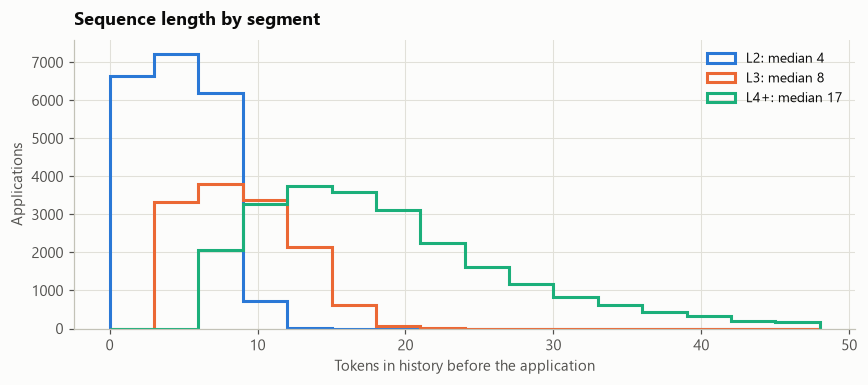

In [8]:
t0 = time.time()
meta, tokens = sq.build_tokens(events, loans)
store = sq.make_store(meta, tokens, df, OOT_START)
has = store.lengths > 0
assert (store.t[store.seq_end[has] - 1] < store.app_t[has]).all(), "PIT: token after the application"
print(f"Tokens: {len(tokens):,}, fields: {tokens.shape[1]} ({time.time() - t0:.0f} s). Token PIT: OK")
display(df.assign(seq_len=store.lengths).groupby("segment").seq_len.describe(percentiles=[0.5, 0.9, 0.99]))
pl.sequence_lengths(store.lengths, df.segment.to_numpy(), FIG)
plt.show()

fold 1/4


  epoch 1: loss=0.6548 valid_gini=0.0376 (6s)


  epoch 2: loss=0.4575 valid_gini=0.4261 (5s)


  epoch 3: loss=0.4209 valid_gini=0.4630 (5s)


  epoch 4: loss=0.4168 valid_gini=0.4747 (5s)


  epoch 5: loss=0.4137 valid_gini=0.4839 (5s)


... (32 outputs left out)

  epoch 7: loss=0.4122 valid_gini=0.4986 (8s)


  epoch 8: loss=0.4110 valid_gini=0.4963 (8s)


  epoch 9: loss=0.4105 valid_gini=0.4959 (8s)


OOF GRU: 214 s


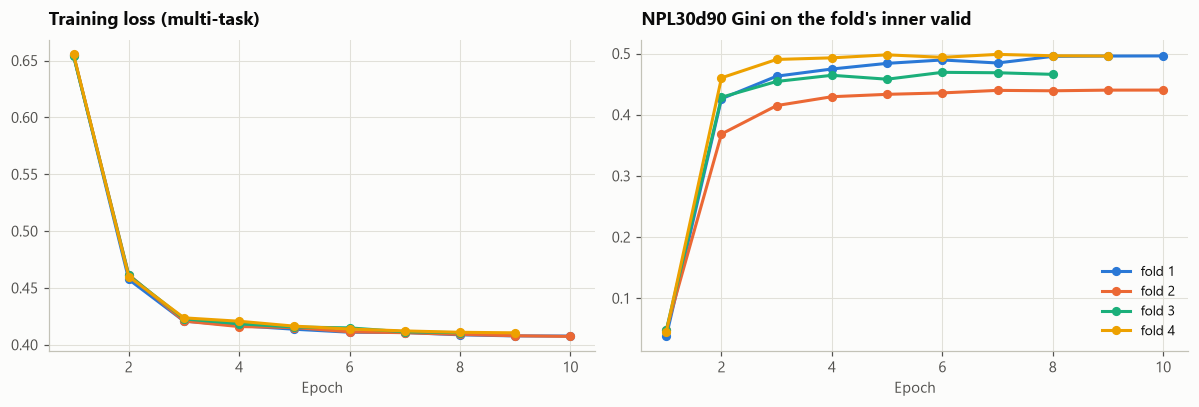

In [9]:
seg_idx = df.segment.map(G.SEGMENT_INDEX).to_numpy()
Y = df[[TARGET] + AUX_TARGETS].to_numpy(float)
pool = df.split.isin(["train", "valid"]).to_numpy()
t0 = time.time()
oof = G.fit_oof(store, seg_idx, Y, df.client_id.to_numpy(), pool, GRU_CFG, n_folds=4)
df["gru_score"] = oof.score
print(f"OOF GRU: {time.time() - t0:.0f} s")
pl.gru_learning_curves(oof.histories, FIG)
plt.show()

Gini of gru_score alone (OOF on train/valid, mean of folds on OOT):


,train,valid,oot
all,0.4737,0.4787,0.4669
L2,0.3959,0.4007,0.3849
L3,0.4570,0.4764,0.4595
L4+,0.5460,0.5392,0.5313


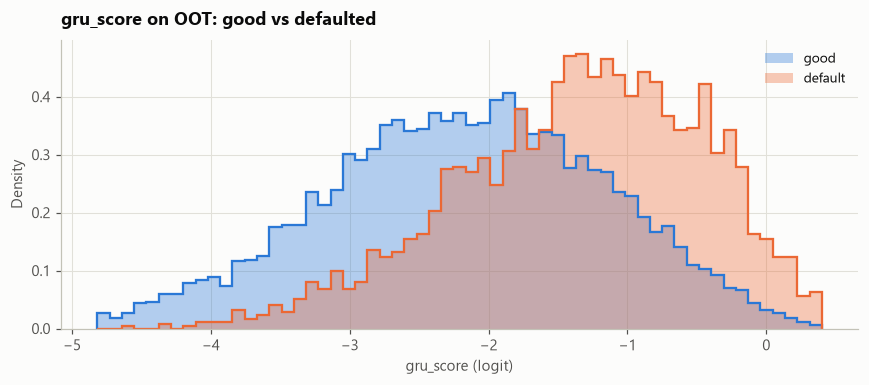

In [10]:
def gini_table(frame, score):
    out = {}
    for s in ["train", "valid", "oot"]:
        part = frame[frame.split.eq(s)]
        out[s] = {"all": mt.gini(part[TARGET], part[score]),
                  **{seg: mt.gini(g[TARGET], g[score]) for seg, g in part.groupby("segment")}}
    return pd.DataFrame(out)

print("Gini of gru_score alone (OOF on train/valid, mean of folds on OOT):")
display(gini_table(df, "gru_score"))
o = df[df.split.eq("oot")]
pl.score_distribution(o.gru_score.to_numpy(), o[TARGET].to_numpy(), "gru_score on OOT: good vs defaulted",
                      "gru_score (logit)", FIG, "21_gru_score_distribution")
plt.show()

The GRU alone sees **only** the event history — no bureau, no application form, no parameters of the current request — and still ranks confidently. Its quality grows with history length, from L2 to L4+. The value of the GRU is not its standalone quality but the fact that it **complements** the tabular features. Stacking below tests this.

## 4. Feature selection: 300+ → final set

Every step uses train and valid only; OOT is not touched.

| Step | Rule | Why |
|---|---|---|
| Technical filters | > 95% missing, one value in > 99.5% of rows | fields without information |
| Leakage | univariate \|Gini\| of the WoE-transformed feature on train > 0.5 | "too good to be true" → review the field's origin |
| Stability | max monthly PSI vs the first three development months > 0.25 | source drift or a change in calculation |
| Predictive power | valid IV < 0.02 (tree bins fitted on train) | weak features; IV on valid is more honest than on train |
| Canaries | the feature does not beat the best noise feature in ≥ 2 of 3 metrics (gain, SHAP, permutation) | separates signal from noise, interactions included |
| MRMR + rank ensemble | sum of 1/rank over gain, SHAP, permutation, IV, MRMR | a stable order instead of a single metric |
| Correlation | \|Spearman ρ\| ≥ 0.8 with an already chosen feature | multicollinearity |
| Saturation curve | the smallest number of features within 0.003 of the best cross-validated Gini (3 client folds on train+valid) | a simpler model of the same quality; a single valid sample is too noisy (Gini SE ≈ 0.01) |

technical: 304 -> 296


leakage: -> 295  flagged: ['coll_calls_cnt_90d']


stability: -> 292  dropped: ['bki_score_v2', 'dig_app_version', 'dig_marketing_source']
iv: -> 219


canaries: -> 38


ensemble+corr: -> 21


saturation: best valid gini 0.5588, chosen n=20
Selection: 240 s


,stage,n_features
0,Initial set,304
1,"Technical filters (missing, constant)",296
2,Suspected leakage (|Gini| > 0.5),295
3,Stability (PSI ≤ 0.25),292
4,Predictive power (valid IV ≥ 0.02),219
5,Importance above noise canaries,38
6,Rank ensemble + correlation (|ρ| < 0.8),21
7,Saturation curve (final set),20


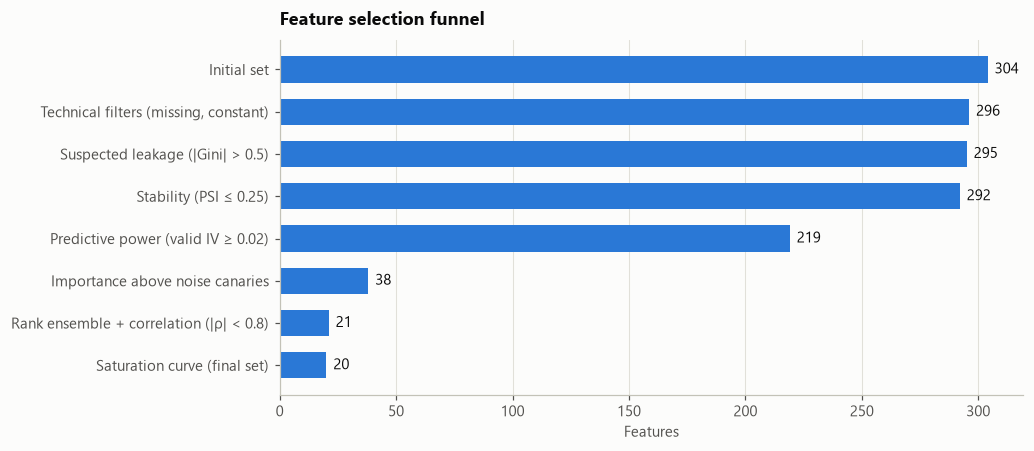

In [11]:
train, valid, test = (df[df.split.eq(s)].reset_index(drop=True) for s in ["train", "valid", "oot"])
t0 = time.time()
selres = sel.select_features(train, valid, FEATURES, TARGET, "application_date", sel.SelectionConfig(n_jobs=N_JOBS))
SELECTED, T = selres.selected, selres.tables
print(f"Selection: {time.time() - t0:.0f} s")
display(selres.funnel)
pl.selection_funnel(selres.funnel, FIG)
plt.show()

In [12]:
print("Technical filters:")
display(T["technical"].query("drop_reason != ''").sort_values(["drop_reason", "feature"]))
print("Suspected leakage (top by univariate Gini on train):")
display(T["leakage"].sort_values("train_gini", ascending=False).head(6))

Technical filters:


,feature,missing_share,n_unique,top_share,drop_reason
297,dig_help_page_views,0.0000,1,1.0000,constant
11,hist_dpd30_cnt_30d,0.0000,1,1.0000,constant
265,app_employer_inn_flag,0.9795,2,0.7650,missing
300,dig_selfie_quality,0.9560,1430,0.0007,missing
299,dig_social_score,0.9685,396,0.0088,missing
264,app_country_code,0.0000,2,0.9996,quasi_constant
282,dig_emulator_flag,0.0000,2,0.9991,quasi_constant
10,hist_dpd15_share_30d,0.6492,2,0.9953,quasi_constant


Suspected leakage (top by univariate Gini on train):


,feature,train_gini,valid_gini,leak_flag
293,coll_calls_cnt_90d,0.9787,0.9791,True
223,bki_score,0.4404,0.4501,False
238,bki_score_v2,0.4250,0.4341,False
169,hist_tw_dpd_mean,0.3893,0.4141,False
164,hist_dpd_mean_last3,0.3843,0.4064,False
105,hist_dpd_mean_365d,0.3791,0.4047,False


`coll_calls_cnt_90d` — "collection calls in 90 days". The field looks like an ordinary historical feature, but in the source the window is counted from the report date, not from the application date. So it captures calls **after** the scored loan was issued. A univariate Gini of about 0.98 when the best honest features are around 0.4 is a signal to check the field's origin, not to celebrate.

Least stable features (PSI over development months):


,feature,psi_max,psi_last,train_iv,valid_iv,n_bins
278,dig_app_version,15.8688,15.8115,0.0042,0.0046,8
238,bki_score_v2,7.8301,7.8301,0.6172,0.6447,9
279,dig_marketing_source,3.0319,2.8580,0.0022,0.0044,6
257,app_weekday,0.0304,0.0294,0.0020,0.0052,7
191,app_loan_number,0.0289,0.0247,0.0274,0.0303,6
123,hist_loans_cnt_all,0.0289,0.0247,0.0274,0.0303,6
178,hist_days_since_first_loan,0.0225,0.0153,0.0434,0.0615,8
98,hist_loans_cnt_365d,0.0211,0.0131,0.0469,0.0396,6
272,dig_page_views_cnt,0.0193,0.0085,0.0085,0.0310,8
102,hist_amount_min_365d,0.0169,0.0117,0.0286,0.0199,9


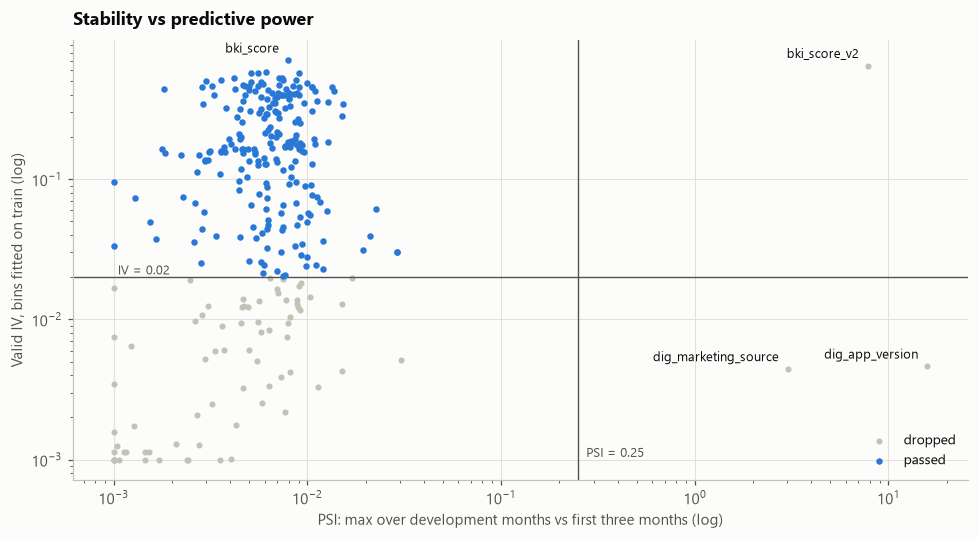

In [13]:
print("Least stable features (PSI over development months):")
display(T["stability"].merge(T["iv"], on="feature").sort_values("psi_max", ascending=False).head(10))
traps = ["dig_app_version", "bki_score_v2", "dig_marketing_source"]
top_iv = T["iv"].sort_values("valid_iv", ascending=False).feature.head(1).tolist()
pl.iv_vs_psi(T["iv"], T["stability"], 0.02, 0.25, annotate=traps + top_iv, out_dir=FIG)
plt.show()

PSI catches the planted traps:
- `bki_score_v2` — the bureau changed its score scale in October 2025;
- `dig_app_version` — the app version grows every month;
- `dig_marketing_source` — a new acquisition channel appeared in November.

On OOT these features would behave differently from training.

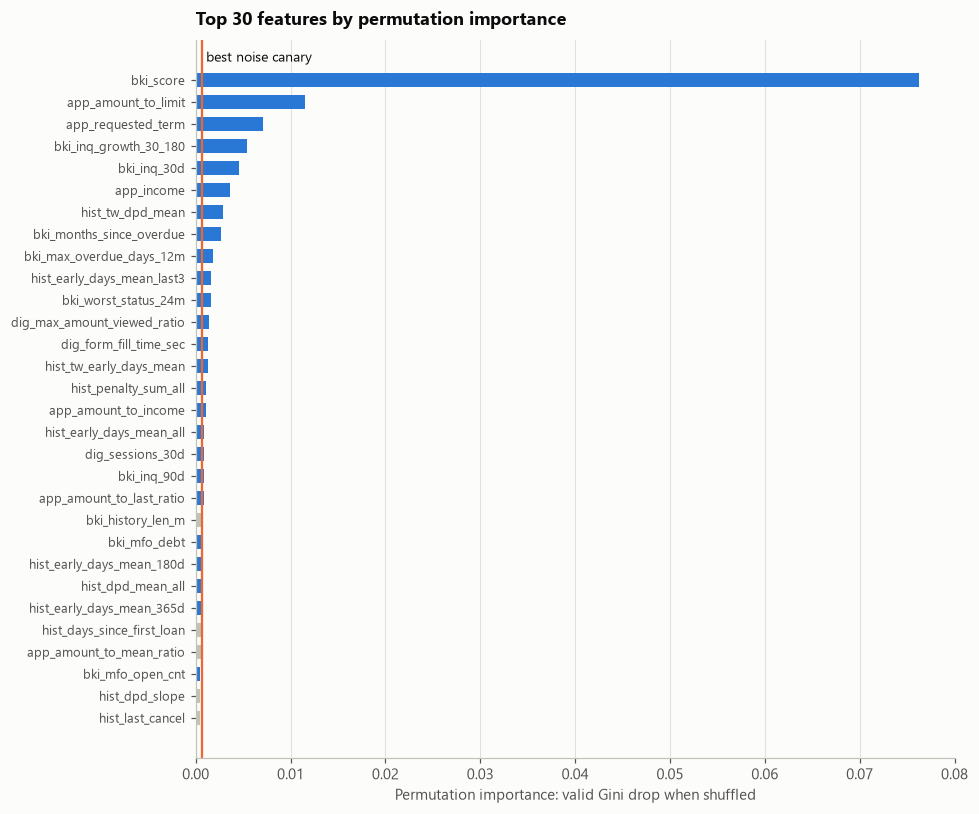

Noise floor (best canary for each metric):


,floor
gain_importance,0.0025
mean_abs_shap,0.0125
permutation_importance,0.0007


In [14]:
pl.evidence_vs_canaries(T["evidence"], T["canary_floor"], top=30, out_dir=FIG)
plt.show()
print("Noise floor (best canary for each metric):")
display(T["canary_floor"].to_frame("floor"))

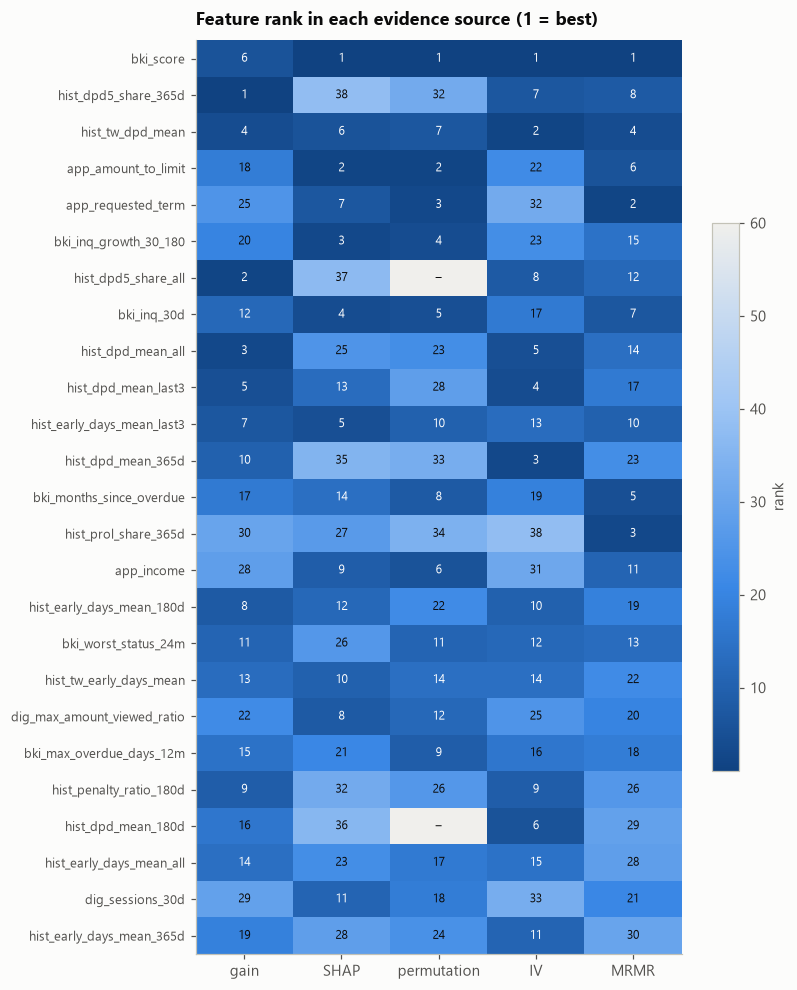

Dropped as correlated with a stronger feature:


,feature,max_corr_with_kept,most_correlated,kept
2,hist_tw_dpd_mean,0.9136,hist_dpd5_share_365d,False
6,hist_dpd5_share_all,0.9985,hist_dpd5_share_365d,False
7,bki_inq_30d,0.9133,bki_inq_growth_30_180,False
8,hist_dpd_mean_all,0.9150,hist_dpd5_share_365d,False
9,hist_dpd_mean_last3,0.8930,hist_dpd5_share_365d,False
11,hist_dpd_mean_365d,0.9165,hist_dpd5_share_365d,False
15,hist_early_days_mean_180d,0.9818,hist_early_days_mean_last3,False
17,hist_tw_early_days_mean,0.9851,hist_early_days_mean_last3,False
18,dig_max_amount_viewed_ratio,0.8931,app_amount_to_limit,False
19,bki_max_overdue_days_12m,0.8547,bki_worst_status_24m,False


In [15]:
pl.ensemble_heatmap(T["ensemble"], top=25, out_dir=FIG)
plt.show()
print("Dropped as correlated with a stronger feature:")
display(T["correlation"].query("~kept").head(10))

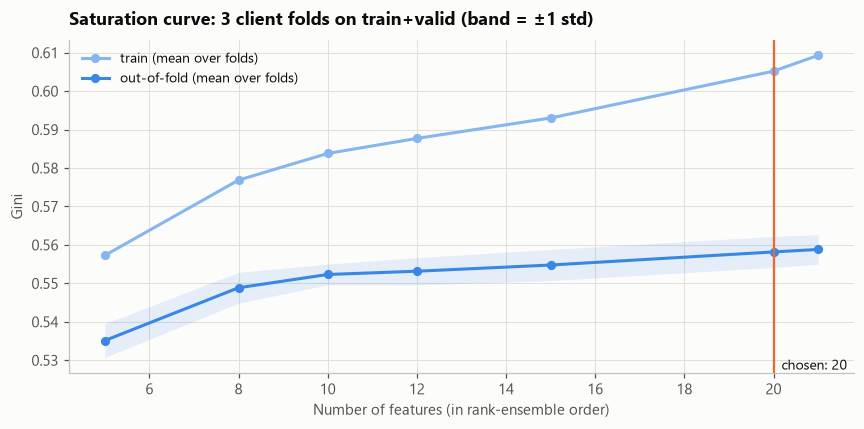

Final set: 20 features


,feature,source,train_iv,valid_iv,n_bins,psi_max,psi_last,ensemble_score,top_sources
0,bki_score,Credit bureau,0.6737,0.7044,9,0.0080,0.0036,4.1667,5
1,hist_dpd5_share_365d,Internal credit history,0.4516,0.5122,6,0.0087,0.0030,1.3254,5
2,app_amount_to_limit,Application form and loan request,0.3312,0.2908,8,0.0062,0.0030,1.2677,5
3,app_requested_term,Application form and loan request,0.0383,0.0673,5,0.0026,0.0014,1.0474,5
4,bki_inq_growth_30_180,Credit bureau,0.2855,0.2773,9,0.0043,0.0017,0.7435,5
5,hist_early_days_mean_last3,Internal credit history,0.4755,0.4631,8,0.0056,0.0014,0.6198,5
6,bki_months_since_overdue,Credit bureau,0.3188,0.4069,9,0.0086,0.0025,0.5079,5
7,hist_prol_share_365d,Internal credit history,0.0306,0.0258,6,0.0058,0.0028,0.4594,5
8,app_income,Application form and loan request,0.0836,0.0910,8,0.0105,0.0088,0.4367,5
9,bki_worst_status_24m,Credit bureau,0.3704,0.4636,6,0.0048,0.0010,0.3805,5


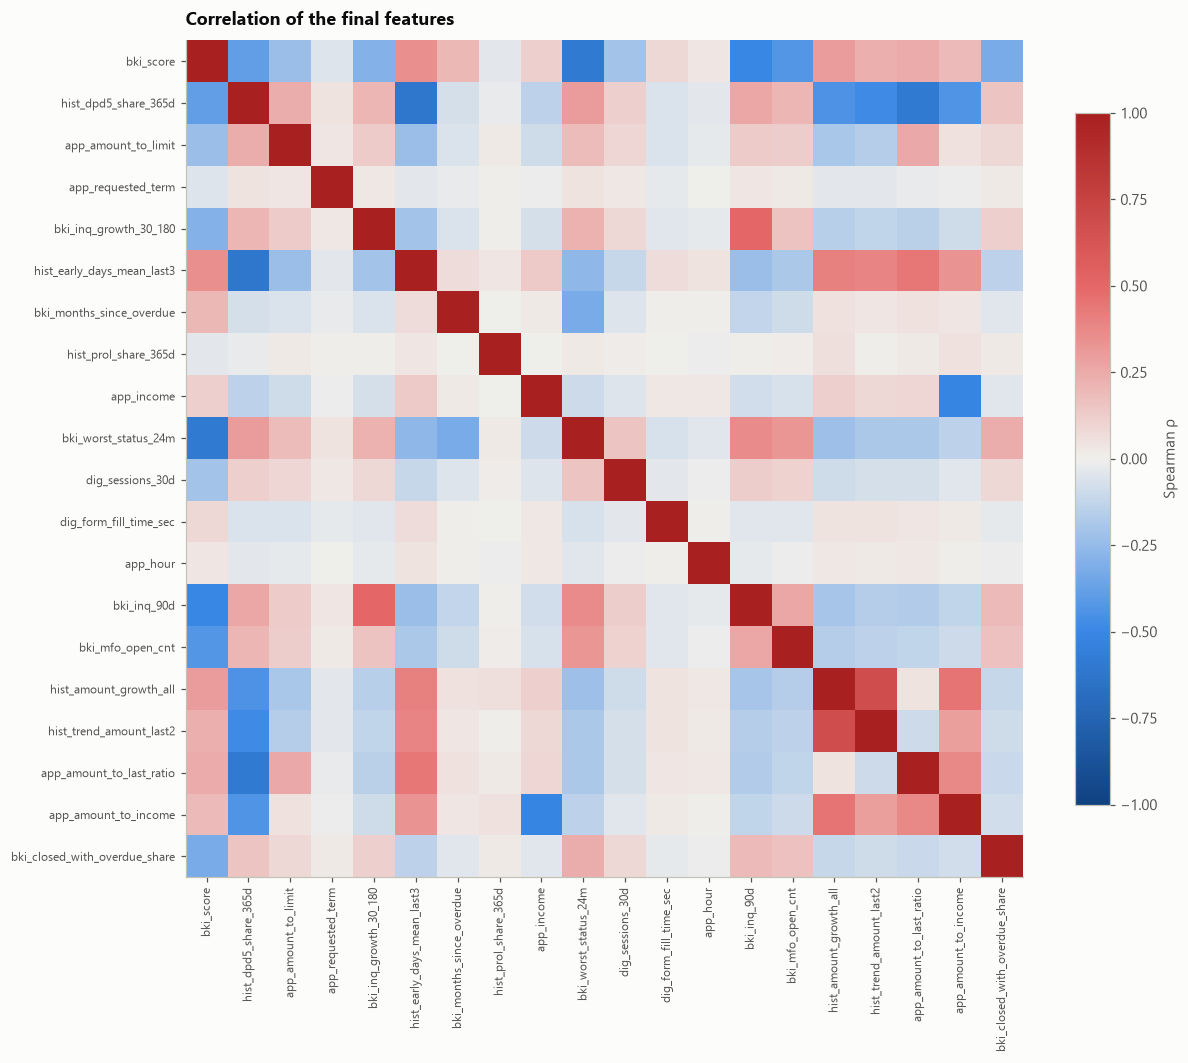

In [16]:
pl.saturation(T["saturation"], len(SELECTED), FIG)
plt.show()
final = (pd.DataFrame({"feature": SELECTED}).merge(T["iv"], on="feature").merge(T["stability"], on="feature")
         .merge(T["ensemble"][["feature", "ensemble_score", "top_sources"]], on="feature"))
final.insert(1, "source", final.feature.str.split("_").str[0].map(fe.GROUPS))
print(f"Final set: {len(SELECTED)} features")
display(final)
pl.correlation_heatmap(train, SELECTED, FIG)
plt.show()

**WoE bins** of the two strongest features: a tree fitted on train picks the boundaries, and the default rate changes monotonically across bins. The same bins are used for IV and for the classic scorecard below.

In [17]:
for f in SELECTED[:2]:
    print(f)
    display(selres.binners[f].table(train[f], train[TARGET]))

bki_score


,bin,n,bad_rate,range,woe
0,-1,1672,0.1507,missing,0.0073
1,0,2613,0.4152,(-inf; 546.5],-1.3779
2,1,1999,0.2936,(546.5; 575.5],-0.8429
3,2,1548,0.2552,(575.5; 592.5],-0.6497
4,3,5188,0.1931,(592.5; 636.5],-0.2907
5,4,4697,0.1375,(636.5; 670.5],0.1152
6,5,4925,0.0979,(670.5; 706.5],0.5001
7,6,2662,0.0721,(706.5; 728.5],0.8320
8,7,7214,0.0408,(728.5; inf],1.4369


hist_dpd5_share_365d


,bin,n,bad_rate,range,woe
0,-1,26,0.7308,missing,-2.6759
1,0,17576,0.0827,(-inf; 0.2404],0.6860
2,1,2887,0.1244,(0.2404; 0.3542],0.2303
3,2,3897,0.1863,(0.3542; 0.5635],-0.2466
4,3,1818,0.2640,(0.5635; 0.775],-0.6959
5,4,6314,0.3006,(0.775; inf],-0.8761


## 5. XGBoost: hyperparameter tuning

Two models are trained with **exactly the same procedure** so that the comparison is fair:
- **XGB base** — the selected tabular features;
- **XGB + GRU** — the same features + `gru_score`.

Optuna (TPE, 40 trials per model) maximises
$$\text{penalized Gini} = \text{Gini}_{valid} - 0.5 \cdot \max(0,\ \text{Gini}_{train} - \text{Gini}_{valid} - 0.03).$$
Plain valid Gini pushes the search towards overfitted configurations. The penalty on a train−valid gap above 0.03 picks models that transfer to OOT more reliably. The number of trees is set by early stopping on valid.

On ~40k rows XGBoost barely speeds up with more threads, so trials run in parallel: 4 trials × 2 threads. Because of this the trial order, and therefore the final parameters, may differ slightly between runs.

Optuna: 498 s


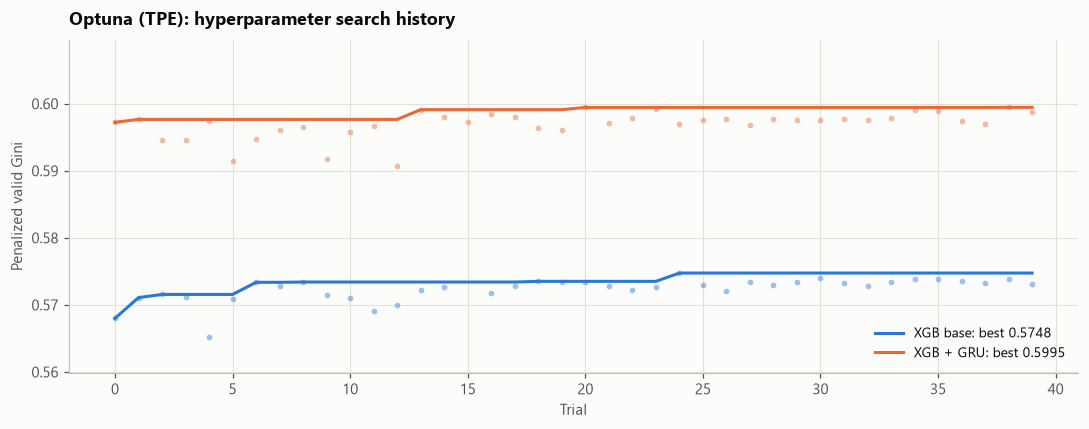

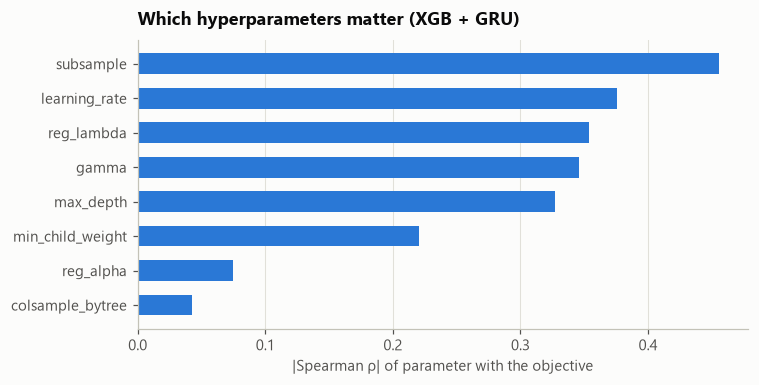

,XGB base,XGB + GRU
learning_rate,0.0211,0.0207
max_depth,2.0000,5.0000
min_child_weight,19.3666,28.3009
subsample,0.6651,0.6053
colsample_bytree,0.7276,0.6348
reg_alpha,4.6384,1.2365
reg_lambda,5.7670,48.5034
gamma,0.5898,1.7099
train_gini,0.5795,0.6276
valid_gini,0.5748,0.5995


In [18]:
STACK = SELECTED + ["gru_score"]
ytr, yva, yte = train[TARGET], valid[TARGET], test[TARGET]
t0 = time.time()
study_base = md.tune_xgb(train[SELECTED], ytr, valid[SELECTED], yva, n_trials=N_TRIALS, seed=SEED, n_jobs=N_JOBS)
study_stack = md.tune_xgb(train[STACK], ytr, valid[STACK], yva, n_trials=N_TRIALS, seed=SEED, n_jobs=N_JOBS)
print(f"Optuna: {time.time() - t0:.0f} s")
pl.optuna_history({"XGB base": study_base, "XGB + GRU": study_stack}, FIG)
plt.show()
pl.param_importance(study_stack, FIG)
plt.show()
best = pd.DataFrame({"XGB base": {**study_base.best_params, **study_base.best_trial.user_attrs},
                     "XGB + GRU": {**study_stack.best_params, **study_stack.best_trial.user_attrs}})
display(best)

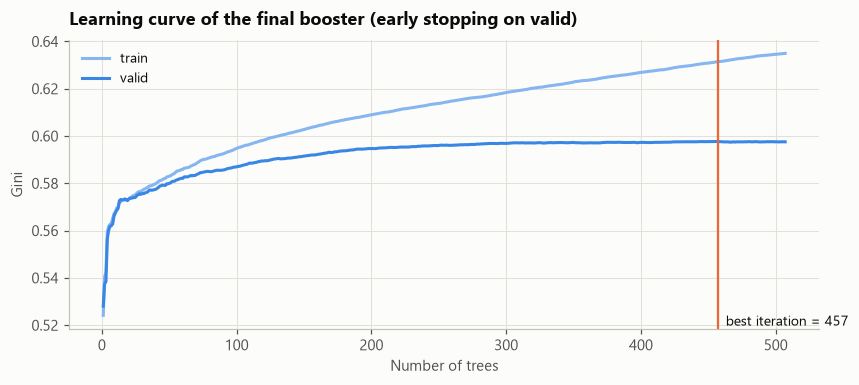

In [19]:
m_base = md.fit_final(study_base.best_params, train[SELECTED], ytr, valid[SELECTED], yva, seed=SEED, n_jobs=N_JOBS)
m_stack = md.fit_final(study_stack.best_params, train[STACK], ytr, valid[STACK], yva, seed=SEED, n_jobs=N_JOBS)
pl.boosting_curve(m_stack, FIG)
plt.show()

**Classic baseline — a WoE scorecard.** The same selected features, tree bins → WoE → logistic regression → points (600 points at 50:1 odds, +20 points double the odds). The scorecard is built in two versions: without the GRU and with `gru_score` as one more feature. This separates how much the new information source gives from how much model complexity gives. If the booster does not beat the scorecard, its complexity is not justified.

In [20]:
scorecard = md.WoeLogitScorecard(SELECTED).fit(train[SELECTED], ytr)
scorecard_gru = md.WoeLogitScorecard(STACK).fit(train[STACK], ytr)
points = scorecard.points_table(train[SELECTED], ytr)
display(points[points.feature.isin(SELECTED[:3])][["feature", "range", "n", "bad_rate", "woe", "points"]])

,feature,range,n,bad_rate,woe,points
0,bki_score,missing,1672,0.1507,0.0073,27.0000
1,bki_score,(-inf; 546.5],2613,0.4152,-1.3779,9.0000
2,bki_score,(546.5; 575.5],1999,0.2936,-0.8429,16.0000
3,bki_score,(575.5; 592.5],1548,0.2552,-0.6497,18.0000
4,bki_score,(592.5; 636.5],5188,0.1931,-0.2907,23.0000
5,bki_score,(636.5; 670.5],4697,0.1375,0.1152,28.0000
6,bki_score,(670.5; 706.5],4925,0.0979,0.5001,33.0000
7,bki_score,(706.5; 728.5],2662,0.0721,0.8320,38.0000
8,bki_score,(728.5; inf],7214,0.0408,1.4369,46.0000
9,hist_dpd5_share_365d,missing,26,0.7308,-2.6759,22.0000


## 6. Model comparison on OOT

Confidence intervals use a **client-level bootstrap** (500 draws): clients are resampled with replacement and all their applications go together. Applications of the same client are dependent, and a row-level bootstrap would give intervals that are too narrow.

In [21]:
MODELS = {"WoE scorecard": "pd_scorecard", "XGB base": "pd_base", "GRU": "gru_score",
          "WoE scorecard + GRU": "pd_scorecard_gru", "XGB + GRU": "pd_stack"}
for part in (train, valid, test):
    part["pd_base"] = m_base.predict_proba(part[SELECTED])[:, 1]
    part["pd_stack"] = m_stack.predict_proba(part[STACK])[:, 1]
    part["pd_scorecard"] = scorecard.predict_proba(part[SELECTED])[:, 1]
    part["pd_scorecard_gru"] = scorecard_gru.predict_proba(part[STACK])[:, 1]
splits = {"train": train, "valid": valid, "oot": test}
results = pd.DataFrame({name: {s: mt.gini(p[TARGET], p[col]) for s, p in splits.items()} for name, col in MODELS.items()}).T
results["KS oot"] = [mt.ks(yte, test[c]) for c in MODELS.values()]
results["train−valid gap"] = results["train"] - results["valid"]
display(results)

,train,valid,oot,KS oot,train−valid gap
WoE scorecard,0.5611,0.5626,0.5225,0.3863,-0.0015
XGB base,0.5829,0.5726,0.5326,0.3966,0.0104
GRU,0.4737,0.4787,0.4669,0.3535,-0.0051
WoE scorecard + GRU,0.5867,0.5886,0.5486,0.4062,-0.0018
XGB + GRU,0.6314,0.5977,0.5570,0.4145,0.0337


Bootstrap: 19 s


,metric,value,ci_low,ci_high,p_value
0,WoE scorecard,0.5225,0.5007,0.5426,NaN
1,XGB base,0.5326,0.5114,0.5520,NaN
2,GRU,0.4669,0.4452,0.4878,NaN
3,WoE scorecard + GRU,0.5486,0.5267,0.5687,NaN
4,XGB + GRU,0.5570,0.5361,0.5771,NaN
5,Δ XGB + GRU − XGB base,0.0244,0.0190,0.0309,0.0000
6,Δ XGB + GRU − WoE scorecard + GRU,0.0084,0.0032,0.0135,0.0000
7,Δ XGB base − WoE scorecard,0.0101,0.0052,0.0146,0.0000
8,Δ WoE scorecard + GRU − WoE scorecard,0.0261,0.0197,0.0333,0.0000
9,Δ XGB + GRU − GRU,0.0901,0.0782,0.1033,0.0000


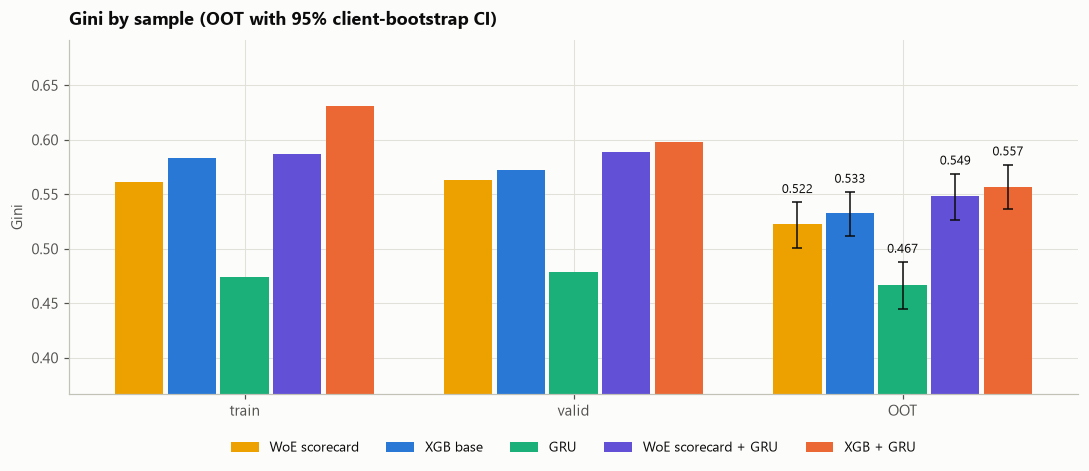

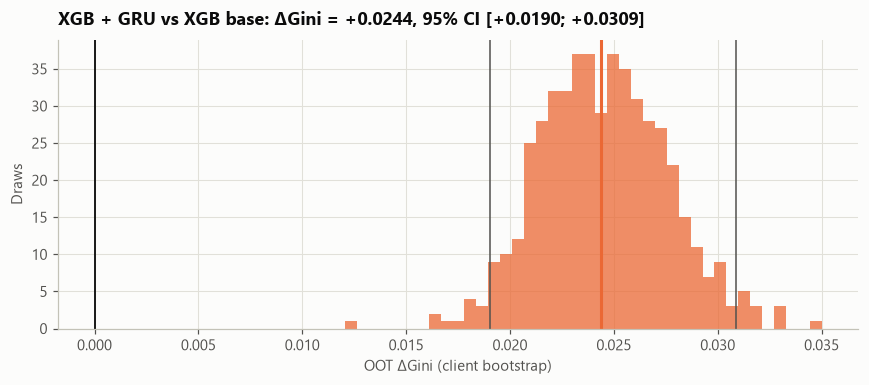

In [22]:
t0 = time.time()
boot = md.bootstrap_gini(yte, {k: test[v] for k, v in MODELS.items()}, test.client_id, n_boot=500, seed=SEED)
point = {k: mt.gini(yte, test[v]) for k, v in MODELS.items()}
summary = md.summarize_bootstrap(boot, point, [("XGB + GRU", "XGB base"), ("XGB + GRU", "WoE scorecard + GRU"),
                                               ("XGB base", "WoE scorecard"), ("WoE scorecard + GRU", "WoE scorecard"),
                                               ("XGB + GRU", "GRU")])
print(f"Bootstrap: {time.time() - t0:.0f} s")
display(summary)
ci = summary.set_index("metric").loc[list(MODELS), ["ci_low", "ci_high"]]
pl.gini_comparison(results[["train", "valid", "oot"]], ci, FIG)
plt.show()
d_uplift = (boot["XGB + GRU"] - boot["XGB base"]).to_numpy()
pl.delta_bootstrap(d_uplift, point["XGB + GRU"] - point["XGB base"], "XGB + GRU vs XGB base", FIG)
plt.show()

,applications,bad rate,WoE scorecard,XGB base,GRU,WoE scorecard + GRU,XGB + GRU,Δ stack−base,CI low,CI high
segment,,,,,,,,,,
L2,5905,0.1865,0.4646,0.4728,0.3849,0.4988,0.5101,0.0374,0.0267,0.0500
L3,3819,0.1767,0.5183,0.5330,0.4595,0.5479,0.5537,0.0207,0.0094,0.0328
L4+,7059,0.1547,0.5725,0.5804,0.5313,0.5894,0.5955,0.0152,0.0059,0.0243


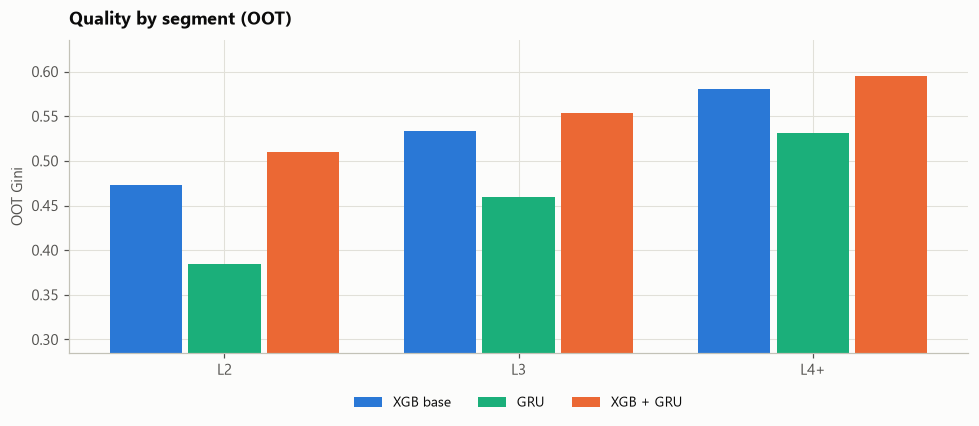

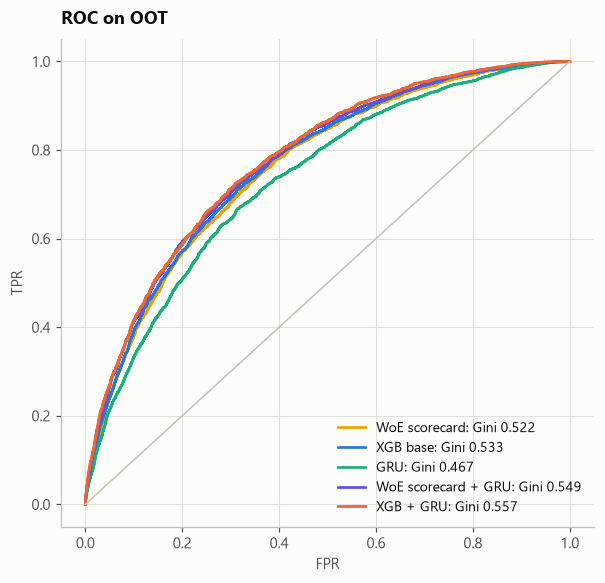

In [23]:
seg_rows = []
for seg, g in test.groupby("segment"):
    b = md.bootstrap_gini(g[TARGET], {"base": g.pd_base, "stack": g.pd_stack}, g.client_id, n_boot=300, seed=SEED)
    d = b["stack"] - b["base"]
    seg_rows.append({"segment": seg, "applications": len(g), "bad rate": g[TARGET].mean(),
                     **{name: mt.gini(g[TARGET], g[col]) for name, col in MODELS.items()},
                     "Δ stack−base": mt.gini(g[TARGET], g.pd_stack) - mt.gini(g[TARGET], g.pd_base),
                     "CI low": d.quantile(0.025), "CI high": d.quantile(0.975)})
by_segment = pd.DataFrame(seg_rows).set_index("segment")
display(by_segment)
pl.gini_by_segment(by_segment[["XGB base", "GRU", "XGB + GRU"]], FIG)
plt.show()
pl.roc_curves({name: (yte, test[col]) for name, col in MODELS.items()}, FIG)
plt.show()

## 7. Interpretation: SHAP

SHAP values are computed by XGBoost itself (`pred_contribs=True`): exact TreeSHAP without a separate library. Sample — 4,000 OOT applications.

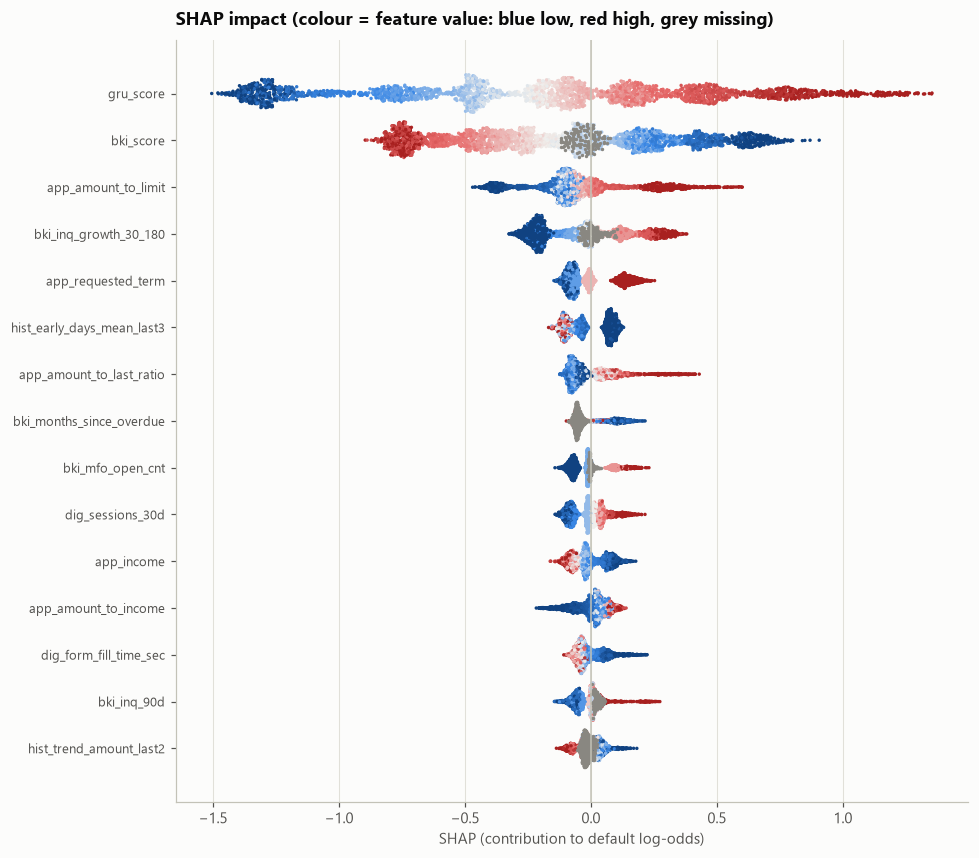

,mean |SHAP|
gru_score,0.5802
bki_score,0.3839
app_amount_to_limit,0.1551
bki_inq_growth_30_180,0.1549
app_requested_term,0.0849
hist_early_days_mean_last3,0.0808
app_amount_to_last_ratio,0.0787
bki_months_since_overdue,0.0674
bki_mfo_open_cnt,0.0601
dig_sessions_30d,0.0583


In [24]:
xs = test[STACK].sample(4000, random_state=SEED)
contrib = m_stack.get_booster().predict(xgb.DMatrix(xs), pred_contribs=True, iteration_range=(0, m_stack.best_iteration + 1))
shap_values = contrib[:, :-1]
shap_imp = pd.Series(np.abs(shap_values).mean(0), index=STACK).sort_values(ascending=False)
pl.shap_beeswarm(shap_values, xs, top=15, out_dir=FIG)
plt.show()
display(shap_imp.head(10).to_frame("mean |SHAP|"))

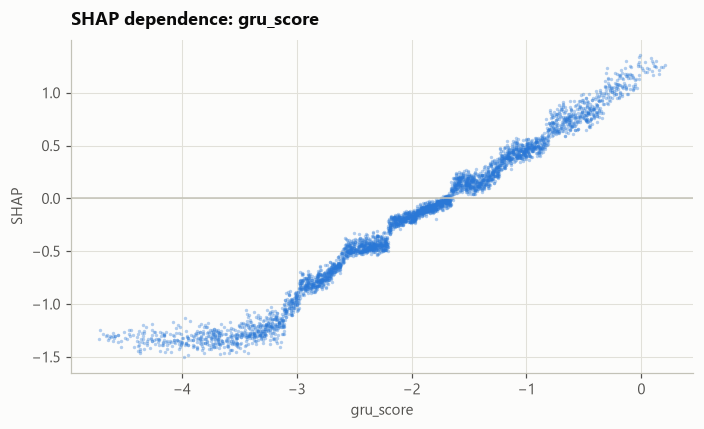

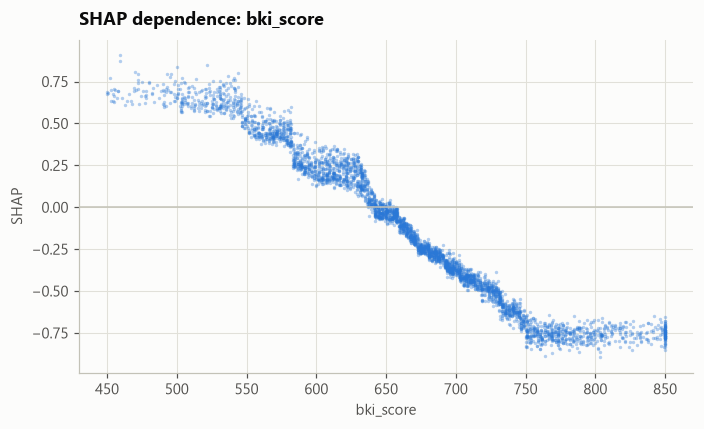

In [25]:
pl.shap_dependence(xs["gru_score"].to_numpy(), shap_values[:, STACK.index("gru_score")], "gru_score", FIG, "61_shap_dependence_gru_score")
plt.show()
top_tab = next(f for f in shap_imp.index if f != "gru_score")
pl.shap_dependence(xs[top_tab].to_numpy(), shap_values[:, STACK.index(top_tab)], top_tab, FIG, "62_shap_dependence_top_feature")
plt.show()

## 8. Stability and calibration

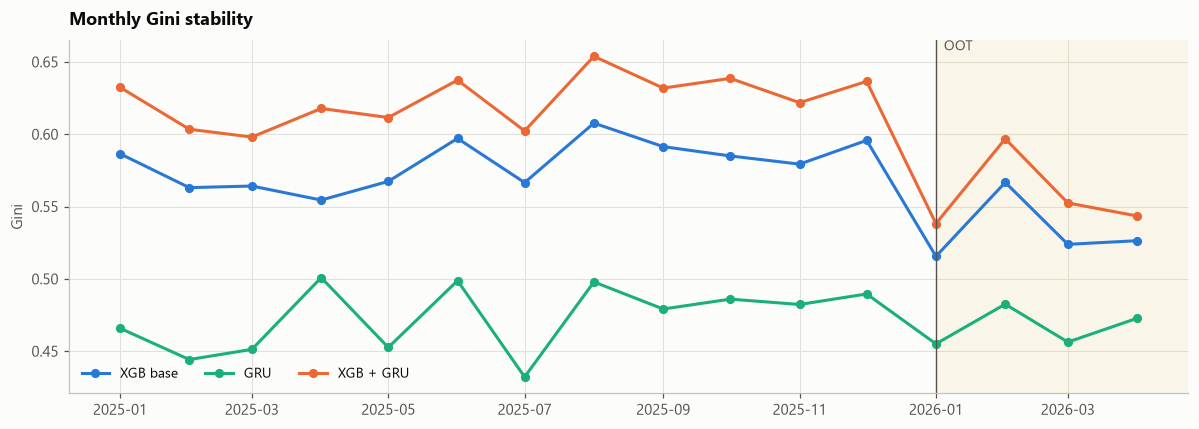

,score PSI train → OOT
WoE scorecard,0.0017
XGB base,0.0011
GRU,0.0016
WoE scorecard + GRU,0.0003
XGB + GRU,0.0006


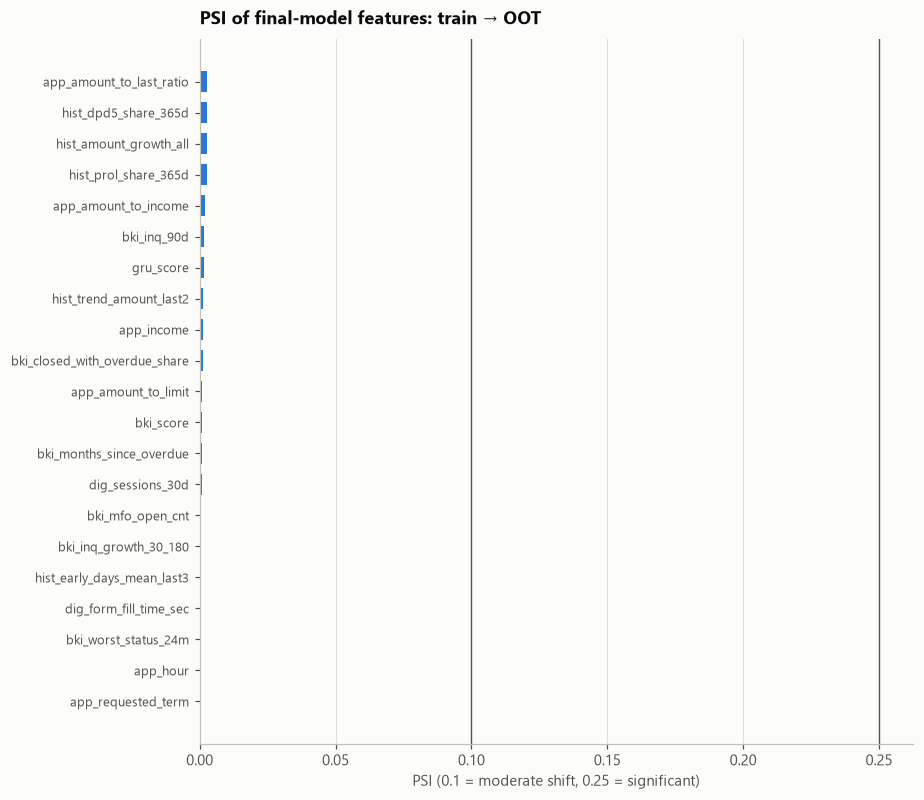

In [26]:
allp = pd.concat([train, valid, test], ignore_index=True)
allp["month"] = allp.application_date.dt.to_period("M").dt.to_timestamp()
monthly = mt.gini_by_period(allp, "month", TARGET, list(MODELS.values())).rename(columns={v: k for k, v in MODELS.items()})
pl.monthly_gini(monthly, ["XGB base", "GRU", "XGB + GRU"], OOT_START, FIG)
plt.show()
score_psi = pd.Series({name: mt.psi(train[col], test[col]) for name, col in MODELS.items()}, name="score PSI train → OOT")
display(score_psi.to_frame())
feat_psi = pd.Series({f: mt.psi(train[f], test[f]) for f in STACK})
pl.psi_bars(feat_psi, FIG)
plt.show()

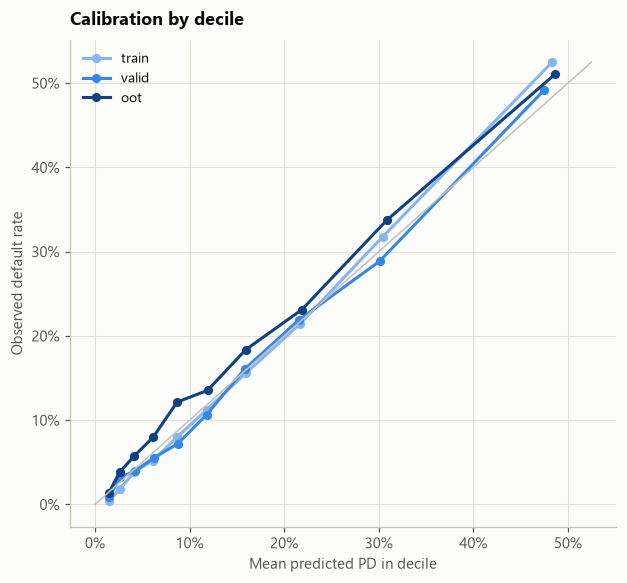

,train,valid,oot
mean PD,0.1513,0.1500,0.1523
observed NPL30d90,0.1518,0.1473,0.1709


In [27]:
calib = {s: mt.calibration_table(p[TARGET], p["pd_stack"]) for s, p in splits.items()}
pl.calibration(calib, FIG)
plt.show()
display(pd.DataFrame({s: {"mean PD": p.pd_stack.mean(), "observed NPL30d90": p[TARGET].mean()} for s, p in splits.items()}))

On OOT the ranking holds while the default rate went up (macro shift), so PD is systematically below the observed rate. Before deployment this is fixed by **recalibration** on a recent window without retraining the model: an intercept shift on the logit scale or isotonic regression. Risk grades are built from train PD quantiles and must stay monotonic on every sample.

,grade,loans,avg_pd,min_pd,max_pd,bad_rate,bads,share,cum_share,cum_bad_rate,cum_bad_capture
0,1,1658,0.0146,0.0079,0.0200,0.0139,23,0.0988,0.0988,0.0139,1.0000
1,2,1720,0.0264,0.0200,0.0332,0.0384,66,0.1025,0.2013,0.0263,0.9920
2,3,1644,0.0414,0.0332,0.0505,0.0566,93,0.0980,0.2992,0.0362,0.9690
3,4,1698,0.0616,0.0506,0.0730,0.0801,136,0.1012,0.4004,0.0473,0.9365
4,5,1661,0.0869,0.0731,0.1013,0.1216,202,0.0990,0.4994,0.0620,0.8891
5,6,1682,0.1188,0.1014,0.1370,0.1344,226,0.1002,0.5996,0.0741,0.8187
6,7,1693,0.1594,0.1370,0.1853,0.1843,312,0.1009,0.7005,0.0900,0.7399
7,8,1589,0.2171,0.1854,0.2526,0.2272,361,0.0947,0.7951,0.1063,0.6311
8,9,1699,0.3038,0.2527,0.3668,0.3355,570,0.1012,0.8964,0.1322,0.5052
9,10,1739,0.4822,0.3669,0.7604,0.5055,879,0.1036,1.0000,0.1709,0.3065


Strictly monotonic bad rate across grades: {'train': True, 'valid': True, 'oot': True}


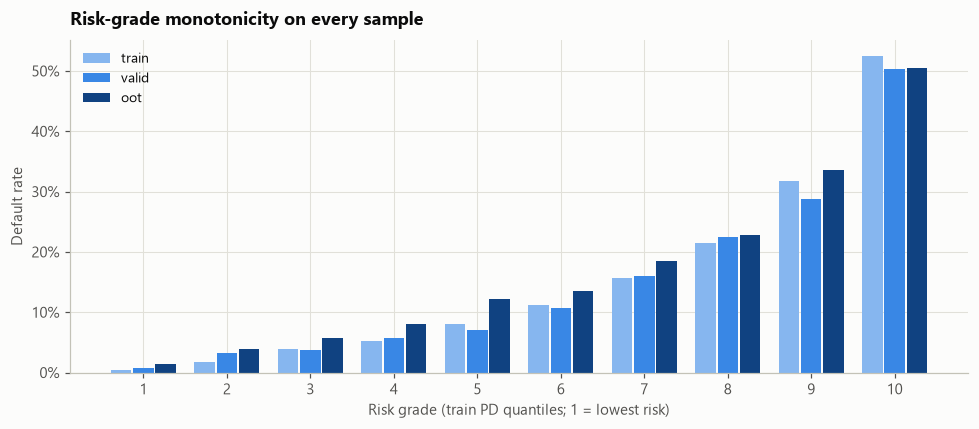

In [28]:
edges = mt.fit_grade_edges(train.pd_stack, 10)
grades = {s: mt.risk_grade_table(p[TARGET].to_numpy(), p.pd_stack.to_numpy(), mt.apply_grade_edges(p.pd_stack, edges))
          for s, p in splits.items()}
display(grades["oot"])
monotone = {s: bool(np.all(np.diff(t.bad_rate.to_numpy()) > 0)) for s, t in grades.items()}
print("Strictly monotonic bad rate across grades:", monotone)
pl.risk_grades(grades, FIG)
plt.show()

## 9. Business impact: the strategy curve

Applications are approved in order of increasing PD. For each approval rate we look at the default rate among approved loans. The lower the curve, the smaller the losses at the same volume of loans.

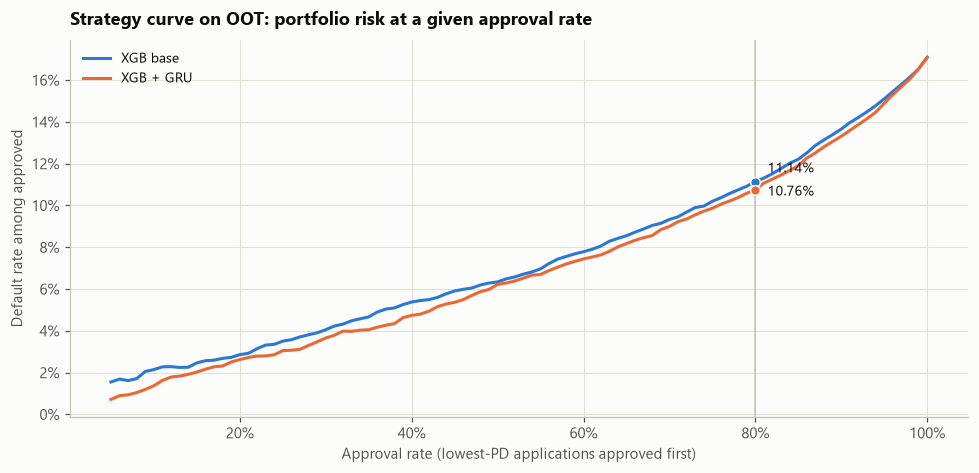

,approval rate,bad rate: XGB base,bad rate: XGB + GRU,relative reduction
0,0.6000,0.0779,0.0744,0.0446
1,0.7000,0.0933,0.0900,0.0356
2,0.8000,0.1114,0.1076,0.0341
3,0.9000,0.1366,0.1331,0.0252


At a portfolio risk of 11.14% (base model at 80% approval) the GRU model approves 81% of applications


In [29]:
curves = {name: mt.approval_curve(yte, test[MODELS[name]]) for name in ["XGB base", "XGB + GRU"]}
pl.approval_curves(curves, at=0.8, out_dir=FIG)
plt.show()
rows = []
for ar in [0.6, 0.7, 0.8, 0.9]:
    b = np.interp(ar, curves["XGB base"].approval_rate, curves["XGB base"].bad_rate)
    s = np.interp(ar, curves["XGB + GRU"].approval_rate, curves["XGB + GRU"].bad_rate)
    rows.append({"approval rate": ar, "bad rate: XGB base": b, "bad rate: XGB + GRU": s, "relative reduction": 1 - s / b})
business = pd.DataFrame(rows)
display(business)
# the same portfolio risk as the base model at 80% approval: how much more can be approved
target_br = np.interp(0.8, curves["XGB base"].approval_rate, curves["XGB base"].bad_rate)
c = curves["XGB + GRU"]
ar_same_risk = float(c.loc[c.bad_rate <= target_br, "approval_rate"].max())
print(f"At a portfolio risk of {target_br:.2%} (base model at 80% approval) the GRU model approves {ar_same_risk:.0%} of applications")

## 10. Deployment readiness

- **GRU without torch.** The weights of the four folds are exported to numpy, and the forward pass is rewritten with the `torch.nn.GRU` equations. Production does not need torch, and scoring one application is a loop over ≤128 tokens. Parity is checked on OOT applications.
- **Artefacts**: boosters (XGBoost JSON format), GRU weights, token standardisation statistics, the feature list, hyperparameters and metrics in `model_card.json`.

In [30]:
scorer = G.GruNumpyScorer(oof.models, GRU_CFG.max_len)
ix = np.flatnonzero(df.split.eq("oot").to_numpy())[:300]
xb, L = G.make_batch(ix, store, GRU_CFG.max_len)
np_logit = np.array([scorer.logit(xb[i, :L[i]].numpy(), seg_idx[ix[i]]) for i in range(len(ix))])
parity = float(np.abs(np_logit - df.gru_score.to_numpy()[ix]).max())
print(f"max |numpy logit − torch logit| on {len(ix)} OOT applications: {parity:.1e}")
assert parity < 1e-4

max |numpy logit − torch logit| on 300 OOT applications: 4.7e-07


In [31]:
ARTEFACTS_DIR.mkdir(parents=True, exist_ok=True)
m_base.save_model(ARTEFACTS_DIR / "xgb_base.json")
m_stack.save_model(ARTEFACTS_DIR / "xgb_stack.json")
torch.save([m.state_dict() for m in oof.models], ARTEFACTS_DIR / "gru_folds.pt")
np.save(ARTEFACTS_DIR / "token_mu_sd.npy", np.stack([store.mu, store.sd]))
card = {
    "target": TARGET, "oot_start": str(OOT_START.date()),
    "selected_features": SELECTED, "stack_features": STACK, "token_fields": store.fields,
    "gru_config": oof.config, "xgb_base_params": study_base.best_params, "xgb_stack_params": study_stack.best_params,
    "gini": results[["train", "valid", "oot"]].round(4).to_dict(orient="index"),
    "oot_delta_stack_vs_base": summary.set_index("metric").loc["Δ XGB + GRU − XGB base", ["value", "ci_low", "ci_high"]].round(4).to_dict(),
    "gru_numpy_parity": parity,
}
(ARTEFACTS_DIR / "model_card.json").write_text(json.dumps(card, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved:", sorted(p.name for p in ARTEFACTS_DIR.iterdir()))

Saved: ['gru_folds.pt', 'model_card.json', 'token_mu_sd.npy', 'xgb_base.json', 'xgb_stack.json']


## 11. Conclusions

In [32]:
d = summary.set_index("metric")
up = d.loc["Δ XGB + GRU − XGB base"]


def delta_txt(key, better, same):
    r = d.loc[key]
    ci = f"Δ {r['value']:+.3f}, 95% CI [{r['ci_low']:+.3f}; {r['ci_high']:+.3f}]"
    return f"{better} ({ci})" if r["ci_low"] > 0 else f"{same} ({ci})"


woe_txt = delta_txt("Δ XGB base − WoE scorecard", "without the GRU the booster is significantly better than the WoE scorecard on the same features",
                    "without the GRU the booster is on par with the WoE scorecard on the same features")
woe_gru_txt = delta_txt("Δ XGB + GRU − WoE scorecard + GRU", "with the GRU the booster is significantly better than the scorecard with the same `gru_score`",
                        "with the GRU the booster is on par with the scorecard with the same `gru_score`")
gain_lr = d.loc["Δ WoE scorecard + GRU − WoE scorecard", "value"]
seg_txt = ", ".join(f"{s} {r['Δ stack−base']:+.3f}" for s, r in by_segment.iterrows())
br80 = business.set_index("approval rate").loc[0.8]
psi_txt = "< 0.001" if score_psi["XGB + GRU"] < 0.001 else f"= {score_psi['XGB + GRU']:.3f}"
display(Markdown(f'''
1. **The GRU as feature reconstruction works.** `gru_score` alone reaches a Gini of {point["GRU"]:.3f} on OOT using only the raw event history.
   Stacked with the tabular features it adds **{up["value"]:+.3f} Gini** on OOT over the same booster without it
   (95% CI [{up["ci_low"]:+.3f}; {up["ci_high"]:+.3f}], client bootstrap); by segment: {seg_txt}.
   The GRU extracts what the aggregates miss: the micro-dynamics inside a loan — how close to the deadline and by which route the client settles an obligation.
2. **Feature selection** reduced {len(FEATURES)} candidates to {len(SELECTED)}. Along the way it removed the leakage (`coll_calls_cnt_90d`), drifting fields (bureau score rescale, app version, new channel), empty and constant fields, noise and duplicates. The saturation curve showed that more features add no quality.
3. **XGBoost with penalized-Gini tuning**: final Gini train / valid / OOT = {results.loc["XGB + GRU", "train"]:.3f} / {results.loc["XGB + GRU", "valid"]:.3f} / {results.loc["XGB + GRU", "oot"]:.3f}.
   The comparison with the scorecard separates the contribution of the information source from that of model complexity. Source: `gru_score` adds {gain_lr:+.3f} Gini to the scorecard. Complexity: {woe_txt}; {woe_gru_txt}.
   Risk grades are monotonic on every sample, score PSI train → OOT {psi_txt}.
4. **Business impact**: at 80% approval the default rate among approved loans falls from {br80["bad rate: XGB base"]:.2%} to {br80["bad rate: XGB + GRU"]:.2%}
   ({br80["relative reduction"]:.1%} relative). At the same portfolio risk {ar_same_risk:.0%} of applications can be approved instead of 80%.
5. **Limitations and next steps**: on OOT the PD level is below the observed rate because of the macro shift, so recalibration is needed before deployment.
   The GRU can be enriched with new event types (applications, rejections, communications) without manual feature engineering — just add a flag to the token.
'''))
print(f"Notebook runtime: {(time.time() - T_START) / 60:.1f} min")


1. **The GRU as feature reconstruction works.** `gru_score` alone reaches a Gini of 0.467 on OOT using only the raw event history.
   Stacked with the tabular features it adds **+0.024 Gini** on OOT over the same booster without it
   (95% CI [+0.019; +0.031], client bootstrap); by segment: L2 +0.037, L3 +0.021, L4+ +0.015.
   The GRU extracts what the aggregates miss: the micro-dynamics inside a loan — how close to the deadline and by which route the client settles an obligation.
2. **Feature selection** reduced 304 candidates to 20. Along the way it removed the leakage (`coll_calls_cnt_90d`), drifting fields (bureau score rescale, app version, new channel), empty and constant fields, noise and duplicates. The saturation curve showed that more features add no quality.
3. **XGBoost with penalized-Gini tuning**: final Gini train / valid / OOT = 0.631 / 0.598 / 0.557.
   The comparison with the scorecard separates the contribution of the information source from that of model complexity. Source: `gru_score` adds +0.026 Gini to the scorecard. Complexity: without the GRU the booster is significantly better than the WoE scorecard on the same features (Δ +0.010, 95% CI [+0.005; +0.015]); with the GRU the booster is significantly better than the scorecard with the same `gru_score` (Δ +0.008, 95% CI [+0.003; +0.014]).
   Risk grades are monotonic on every sample, score PSI train → OOT < 0.001.
4. **Business impact**: at 80% approval the default rate among approved loans falls from 11.14% to 10.76%
   (3.4% relative). At the same portfolio risk 81% of applications can be approved instead of 80%.
5. **Limitations and next steps**: on OOT the PD level is below the observed rate because of the macro shift, so recalibration is needed before deployment.
   The GRU can be enriched with new event types (applications, rejections, communications) without manual feature engineering — just add a flag to the token.


Notebook runtime: 19.4 min
